<div style="background:#FAF7F0; padding:22px 26px; border-left:7px solid #174D38; border-radius:10px; margin:16px 0;">

<h1 style="color:#174D38; margin:0 0 8px 0;">
Cooling Riyadh
</h1>

<h2 style="color:#C5A45A; margin:0 0 18px 0; font-weight:600;">
Mapping Urban Heat and Greening Priorities in Riyadh: A Geospatial Data Science Approach
</h2>

<p style="color:#2B2B2B; margin:0; line-height:1.7; font-size:1.05rem;">
<strong>MUSA 5500 – Geospatial Data Science in Python</strong><br>
<strong>Final Project – Fall 2026</strong><br>
<strong>Alhaylam Fahad Alajmi</strong>
</p>

<hr style="border:none; border-top:1px solid #C5A45A; margin:18px 0;">

<h3 style="color:#174D38; margin:0 0 8px 0;">
Notebook 01 — Data Setup and Building Footprints
</h3>

<p style="color:#2B2B2B; margin:0; line-height:1.7;">
This notebook prepares the core geospatial dataset for the Cooling Riyadh project. It processes Microsoft Building Footprints, creates the 500 m analysis grid, integrates WorldPop population estimates, derives NDVI and land surface temperature from Landsat imagery, and prepares the combined dataset used for later clustering and spatial priority analysis.
</p>

</div>

<div style="background:#FAF7F0; padding:14px 18px; border-left:6px solid #174D38; border-radius:8px; margin:14px 0;">

<h2 style="color:#174D38; margin:0 0 6px 0;">
1. Project Setup and Data Sources
</h2>

<p style="color:#2B2B2B; margin:0; line-height:1.6;">
This section sets up the project paths and loads the main spatial datasets used for the building footprint workflow.
</p>

</div>

In [2]:
from pathlib import Path

import geopandas as gpd
import pandas as pd

project_root = Path.cwd().parent

boundary_path = project_root / "Data" / "boundary" / "Riyadh_Urban_Boundary.gpkg"
links_path = project_root / "Data" / "building_footprints" / "dataset-links.csv"

riyadh_boundary = gpd.read_file(boundary_path)
building_links = pd.read_csv(links_path)

print("Boundary rows:", len(riyadh_boundary))
print("Boundary CRS:", riyadh_boundary.crs)
print("Building links rows:", len(building_links))
print("Building links columns:", building_links.columns.tolist())

Boundary rows: 1
Boundary CRS: PROJCS["World_Mollweide",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Mollweide"],PARAMETER["central_meridian",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["ESRI","54009"]]
Building links rows: 30340
Building links columns: ['Location', 'QuadKey', 'Url', 'Size', 'UploadDate']


<div style="background:#FAF7F0; padding:14px 18px; border-left:6px solid #C5A45A; border-radius:8px; margin:14px 0;">

<h2 style="color:#174D38; margin:0 0 6px 0;">
2. Microsoft Building Footprints
</h2>

<p style="color:#2B2B2B; margin:0; line-height:1.6;">
This section filters the Microsoft Building Footprints dataset for Saudi Arabia, identifies the tiles covering Riyadh, and prepares the building footprint data for the study area.
</p>

</div>

In [3]:
saudi_links = building_links[
    building_links["Location"] == "KingdomofSaudiArabia"
].copy()

print("Saudi Arabia tiles:", len(saudi_links))
print(saudi_links.head())

Saudi Arabia tiles: 306
                   Location    QuadKey  \
16017  KingdomofSaudiArabia  122112333   
16018  KingdomofSaudiArabia  122113222   
16019  KingdomofSaudiArabia  122113223   
16020  KingdomofSaudiArabia  122130033   
16021  KingdomofSaudiArabia  122130100   

                                                     Url     Size  UploadDate  
16017  https://bfppub.z5.web.core.windows.net/2026-08...   13.2KB  2026-08-13  
16018  https://bfppub.z5.web.core.windows.net/2026-08...    7.1KB  2026-08-13  
16019  https://bfppub.z5.web.core.windows.net/2026-08...    3.3KB  2026-08-13  
16020  https://bfppub.z5.web.core.windows.net/2026-08...     452B  2026-08-13  
16021  https://bfppub.z5.web.core.windows.net/2026-08...  235.9KB  2026-08-13  


In [4]:
from math import atan, sinh, pi, degrees
from shapely.geometry import box

# Convert Riyadh boundary to WGS84
riyadh_wgs84 = riyadh_boundary.to_crs(epsg=4326)
riyadh_geom = riyadh_wgs84.geometry.iloc[0]


def quadkey_to_tile_xy(quadkey):
    """Convert Bing Maps QuadKey to tile X, Y, and zoom."""
    quadkey = str(quadkey)

    tile_x = 0
    tile_y = 0
    zoom = len(quadkey)

    for i, digit in enumerate(quadkey):
        bit = zoom - i - 1
        mask = 1 << bit

        if digit == "1":
            tile_x |= mask
        elif digit == "2":
            tile_y |= mask
        elif digit == "3":
            tile_x |= mask
            tile_y |= mask

    return tile_x, tile_y, zoom


def tile_y_to_latitude(tile_y, zoom):
    """Convert Bing tile Y coordinate to latitude."""
    n = 2 ** zoom
    mercator_y = pi * (1 - 2 * tile_y / n)
    return degrees(atan(sinh(mercator_y)))


def quadkey_to_polygon(quadkey):
    """Create WGS84 polygon representing a QuadKey tile."""
    tile_x, tile_y, zoom = quadkey_to_tile_xy(quadkey)

    n = 2 ** zoom

    west = tile_x / n * 360.0 - 180.0
    east = (tile_x + 1) / n * 360.0 - 180.0

    north = tile_y_to_latitude(tile_y, zoom)
    south = tile_y_to_latitude(tile_y + 1, zoom)

    return box(west, south, east, north)


saudi_links["QuadKey"] = saudi_links["QuadKey"].astype(str)

saudi_links["geometry"] = saudi_links["QuadKey"].apply(quadkey_to_polygon)

saudi_tiles = gpd.GeoDataFrame(
    saudi_links,
    geometry="geometry",
    crs="EPSG:4326"
)

riyadh_tiles = saudi_tiles[
    saudi_tiles.intersects(riyadh_geom)
].copy()

print("Tiles intersecting Riyadh:", len(riyadh_tiles))
print(riyadh_tiles[["QuadKey", "Size", "UploadDate"]])

Tiles intersecting Riyadh: 2
         QuadKey    Size  UploadDate
16249  123022032  75.0MB  2026-08-13
16269  123022210   7.5MB  2026-08-13


In [5]:
import requests

download_dir = project_root / "Data" / "building_footprints" / "riyadh_tiles"
download_dir.mkdir(parents=True, exist_ok=True)

for _, row in riyadh_tiles.iterrows():
    quadkey = row["QuadKey"]
    url = row["Url"]

    output_path = download_dir / f"{quadkey}.csv.gz"

    print(f"Downloading QuadKey {quadkey}...")

    response = requests.get(url, stream=True)
    response.raise_for_status()

    with open(output_path, "wb") as file:
        for chunk in response.iter_content(chunk_size=1024 * 1024):
            if chunk:
                file.write(chunk)

    print(f"Saved: {output_path.name}")

print("Download complete.")

Saved: 123022032.csv.gz
Saved: 123022210.csv.gz
Download complete.


<div style="background:#FAF7F0; padding:14px 18px; border-left:6px solid #174D38; border-radius:8px; margin:14px 0;">

<h2 style="color:#174D38; margin:0 0 6px 0;">
3. Load and Prepare Riyadh Building Footprints
</h2>

<p style="color:#2B2B2B; margin:0; line-height:1.6;">
This section reads the selected Microsoft building footprint tiles and prepares the building geometries for the Riyadh study area.
</p>

</div>

In [6]:
# Load the downloaded Microsoft building footprint tiles

import gzip
import json
import geopandas as gpd
from shapely.geometry import shape

tiles_dir = (
    project_root
    / "Data"
    / "building_footprints"
    / "riyadh_tiles"
)

tile_files = sorted(tiles_dir.glob("*.csv.gz"))

print("Building footprint tiles found:", len(tile_files))

building_features = []

for file in tile_files:
    print(f"Reading {file.name}...")

    with gzip.open(file, "rt", encoding="utf-8") as f:
        for line in f:
            feature = json.loads(line)

            building_features.append(
                {
                    "height": feature["properties"].get("height"),
                    "confidence": feature["properties"].get("confidence"),
                    "geometry": shape(feature["geometry"]),
                }
            )

riyadh_buildings = gpd.GeoDataFrame(
    building_features,
    geometry="geometry",
    crs="EPSG:4326"
)

print("Buildings loaded:", len(riyadh_buildings))
print("CRS:", riyadh_buildings.crs)

riyadh_buildings.head()

Building footprint tiles found: 2
Reading 123022032.csv.gz...
Reading 123022210.csv.gz...
Buildings loaded: 869646
CRS: EPSG:4326


,height,confidence,geometry
0,-1.0,-1.0,"POLYGON ((46.67356 24.72151, 46.67348 24.72169..."
1,-1.0,-1.0,"POLYGON ((46.40534 24.78541, 46.4054 24.78604,..."
2,-1.0,-1.0,"POLYGON ((46.6736 24.80434, 46.67373 24.80438,..."
3,-1.0,-1.0,"POLYGON ((46.40691 25.11747, 46.40695 25.11748..."
4,-1.0,-1.0,"POLYGON ((46.67372 24.85615, 46.67399 24.85625..."


<div style="background:#FAF7F0; padding:14px 18px; border-left:6px solid #C5A45A; border-radius:8px; margin:14px 0;">

<h2 style="color:#174D38; margin:0 0 6px 0;">
4. Clip Buildings to the Riyadh Study Area
</h2>

<p style="color:#2B2B2B; margin:0; line-height:1.6;">
This step clips the Microsoft building footprints to the Riyadh study boundary so that only buildings inside the project area are retained.
</p>

</div>

In [7]:
# Repair invalid building geometries, then clip to the Riyadh study boundary

# Reproject the Riyadh boundary to match the building footprint CRS
riyadh_boundary_wgs84 = riyadh_boundary.to_crs(epsg=4326)

# Repair invalid building geometries
riyadh_buildings_fixed = riyadh_buildings.copy()

invalid_mask = ~riyadh_buildings_fixed.is_valid

riyadh_buildings_fixed.loc[invalid_mask, "geometry"] = (
    riyadh_buildings_fixed.loc[invalid_mask, "geometry"]
    .make_valid()
)

# Clip buildings to the Riyadh study boundary
riyadh_buildings_clipped = gpd.clip(
    riyadh_buildings_fixed,
    riyadh_boundary_wgs84
)

riyadh_buildings_clipped = (
    riyadh_buildings_clipped
    .reset_index(drop=True)
)

print("Buildings before clipping:", len(riyadh_buildings))
print("Invalid geometries repaired:", invalid_mask.sum())
print("Buildings inside Riyadh boundary:", len(riyadh_buildings_clipped))
print("CRS:", riyadh_buildings_clipped.crs)

Buildings before clipping: 869646
Invalid geometries repaired: 54
Buildings inside Riyadh boundary: 578681
CRS: EPSG:4326


In [8]:
# Save clipped Riyadh building footprints

building_output = (
    project_root
    / "Data"
    / "building_footprints"
    / "Riyadh_Building_Footprints.gpkg"
)

riyadh_buildings_clipped.to_file(
    building_output,
    driver="GPKG"
)

print("Saved:", building_output)

Saved: C:\Users\Alhaylam Alajmi\Desktop\MUSA 5500\Final Project\Data\building_footprints\Riyadh_Building_Footprints.gpkg


<div style="background:#FAF7F0; padding:14px 18px; border-left:6px solid #174D38; border-radius:8px; margin:14px 0;">

<h2 style="color:#174D38; margin:0 0 6px 0;">
5. Building Area and Density Preparation
</h2>

<p style="color:#2B2B2B; margin:0; line-height:1.6;">
This section prepares the building footprints for area-based analysis. The geometries will be projected to a metric coordinate system so building area can be calculated accurately.
</p>

</div>

In [9]:
# Project building footprints to a metric CRS and calculate building area

riyadh_buildings_metric = riyadh_buildings_clipped.to_crs(epsg=32638)

riyadh_buildings_metric["building_area_m2"] = (
    riyadh_buildings_metric.geometry.area
)

print("Metric CRS:", riyadh_buildings_metric.crs)
print("Buildings:", len(riyadh_buildings_metric))
print("Minimum building area:", round(riyadh_buildings_metric["building_area_m2"].min(), 2), "m²")
print("Maximum building area:", round(riyadh_buildings_metric["building_area_m2"].max(), 2), "m²")
print("Mean building area:", round(riyadh_buildings_metric["building_area_m2"].mean(), 2), "m²")

Metric CRS: EPSG:32638
Buildings: 578681
Minimum building area: 0.0 m²
Maximum building area: 104070.94 m²
Mean building area: 444.46 m²


<div style="background:#FAF7F0; padding:14px 18px; border-left:6px solid #C5A45A; border-radius:8px; margin:14px 0;">

<h2 style="color:#174D38; margin:0 0 6px 0;">
6. Create the 500 m Analysis Grid
</h2>

<p style="color:#2B2B2B; margin:0; line-height:1.6;">
A regular 500 m × 500 m grid will be used as the common spatial unit for comparing building characteristics, population, vegetation, and land surface temperature across Riyadh.
</p>

</div>

In [10]:
# Create a 500 m x 500 m analysis grid over the Riyadh study area

from shapely.geometry import box

riyadh_boundary_metric = riyadh_boundary.to_crs(epsg=32638)

minx, miny, maxx, maxy = riyadh_boundary_metric.total_bounds

cell_size = 500

grid_cells = []

x = minx
while x < maxx:
    y = miny
    while y < maxy:
        grid_cells.append(
            box(
                x,
                y,
                x + cell_size,
                y + cell_size
            )
        )
        y += cell_size
    x += cell_size

riyadh_grid = gpd.GeoDataFrame(
    geometry=grid_cells,
    crs="EPSG:32638"
)

riyadh_grid = gpd.clip(
    riyadh_grid,
    riyadh_boundary_metric
).reset_index(drop=True)

riyadh_grid["grid_id"] = range(1, len(riyadh_grid) + 1)

print("Grid cells created:", len(riyadh_grid))
print("Grid CRS:", riyadh_grid.crs)
print("Cell size:", cell_size, "m")

Grid cells created: 4721
Grid CRS: EPSG:32638
Cell size: 500 m


<div style="background:#FAF7F0; padding:14px 18px; border-left:6px solid #174D38; border-radius:8px; margin:14px 0;">

<h2 style="color:#174D38; margin:0 0 6px 0;">
7. Summarize Building Characteristics by Grid Cell
</h2>

<p style="color:#2B2B2B; margin:0; line-height:1.6;">
This section summarizes the Microsoft building footprints within each 500 m grid cell. The analysis will calculate building count, total building area, and building coverage to describe the built environment across Riyadh.
</p>

</div>

In [11]:
# Summarize building characteristics within each 500 m grid cell

# Add a unique building ID
riyadh_buildings_metric = riyadh_buildings_metric.reset_index(drop=True)
riyadh_buildings_metric["building_id"] = range(1, len(riyadh_buildings_metric) + 1)

# Intersect building footprints with the analysis grid
building_grid_intersection = gpd.overlay(
    riyadh_buildings_metric[["building_id", "geometry"]],
    riyadh_grid[["grid_id", "geometry"]],
    how="intersection"
)

# Calculate the portion of each building falling inside each grid cell
building_grid_intersection["building_area_m2"] = (
    building_grid_intersection.geometry.area
)

# Summarize building metrics by grid cell
building_summary = (
    building_grid_intersection
    .groupby("grid_id")
    .agg(
        building_count=("building_id", "nunique"),
        building_area_m2=("building_area_m2", "sum")
    )
    .reset_index()
)

# Join the building metrics back to the full grid
riyadh_grid_buildings = riyadh_grid.merge(
    building_summary,
    on="grid_id",
    how="left"
)

# Replace empty cells with zero
riyadh_grid_buildings["building_count"] = (
    riyadh_grid_buildings["building_count"]
    .fillna(0)
    .astype(int)
)

riyadh_grid_buildings["building_area_m2"] = (
    riyadh_grid_buildings["building_area_m2"]
    .fillna(0)
)

# Calculate the actual area of each grid cell
riyadh_grid_buildings["grid_area_m2"] = (
    riyadh_grid_buildings.geometry.area
)

# Calculate building coverage percentage
riyadh_grid_buildings["building_coverage_pct"] = (
    riyadh_grid_buildings["building_area_m2"]
    / riyadh_grid_buildings["grid_area_m2"]
) * 100

# Count unique buildings represented in the grid
unique_buildings_represented = (
    building_grid_intersection["building_id"].nunique()
)

print("Grid cells:", len(riyadh_grid_buildings))
print("Unique buildings represented:", unique_buildings_represented)
print(
    "Maximum building coverage:",
    round(riyadh_grid_buildings["building_coverage_pct"].max(), 2),
    "%"
)
print(
    "Mean building coverage:",
    round(riyadh_grid_buildings["building_coverage_pct"].mean(), 2),
    "%"
)

Grid cells: 4721
Unique buildings represented: 578679
Maximum building coverage: 69.9 %
Mean building coverage: 22.41 %


In [12]:
# Save the 500 m grid with building metrics

grid_buildings_output = (
    project_root
    / "Data"
    / "building_footprints"
    / "Riyadh_500m_Grid_Building_Metrics.gpkg"
)

riyadh_grid_buildings.to_file(
    grid_buildings_output,
    driver="GPKG"
)

print("Saved to:")
print(grid_buildings_output)

Saved to:
C:\Users\Alhaylam Alajmi\Desktop\MUSA 5500\Final Project\Data\building_footprints\Riyadh_500m_Grid_Building_Metrics.gpkg


<div style="background:#FAF7F0; padding:14px 18px; border-left:6px solid #C5A45A; border-radius:8px; margin:14px 0;">

<h2 style="color:#174D38; margin:0 0 6px 0;">
8. Integrate Population Data
</h2>

<p style="color:#2B2B2B; margin:0; line-height:1.6;">
This section integrates the WorldPop 2026 population raster with the 500 m analysis grid. Population values will be summarized for each grid cell so population exposure can later be compared with urban heat, vegetation, and building density.
</p>

</div>

In [13]:
# Load the clipped WorldPop population raster

import rasterio

population_path = (
    project_root
    / "Data"
    / "Population"
    / "Riyadh_WorldPop_2026.tif"
)

with rasterio.open(population_path) as src:
    population_crs = src.crs
    population_bounds = src.bounds
    population_nodata = src.nodata
    population_width = src.width
    population_height = src.height

print("Population raster:", population_path.name)
print("CRS:", population_crs)
print("NoData value:", population_nodata)
print("Raster size:", population_width, "x", population_height)
print("Bounds:", population_bounds)

Population raster: Riyadh_WorldPop_2026.tif
CRS: EPSG:4326
NoData value: -99999.0
Raster size: 553 x 474
Bounds: BoundingBox(left=46.488333147, bottom=24.484999902, right=46.949166479, top=24.8799999)


In [14]:
# Summarize WorldPop population within each 500 m grid cell

from rasterstats import zonal_stats

# Reproject the analysis grid to match the WorldPop raster CRS
riyadh_grid_population_wgs84 = riyadh_grid_buildings.to_crs(epsg=4326)

# Calculate population sum within each grid cell
population_stats = zonal_stats(
    riyadh_grid_population_wgs84,
    population_path,
    stats=["sum"],
    nodata=-99999
)

# Keep the main analysis grid in the metric CRS
riyadh_grid_population = riyadh_grid_buildings.copy()

riyadh_grid_population["population"] = [
    stat["sum"] if stat["sum"] is not None else 0
    for stat in population_stats
]

print("Grid cells:", len(riyadh_grid_population))
print(
    "Total population represented:",
    round(riyadh_grid_population["population"].sum())
)
print(
    "Maximum population in one grid cell:",
    round(riyadh_grid_population["population"].max())
)

Grid cells: 4721
Total population represented: 6281695
Maximum population in one grid cell: 2962


In [15]:
# Save the 500 m analysis grid with building and population metrics

grid_population_output = (
    project_root
    / "Data"
    / "Population"
    / "Riyadh_500m_Grid_Buildings_Population.gpkg"
)

riyadh_grid_population.to_file(
    grid_population_output,
    driver="GPKG"
)

print("Saved to:")
print(grid_population_output)

Saved to:
C:\Users\Alhaylam Alajmi\Desktop\MUSA 5500\Final Project\Data\Population\Riyadh_500m_Grid_Buildings_Population.gpkg


<div style="background:#FAF7F0; padding:14px 18px; border-left:6px solid #174D38; border-radius:8px; margin:14px 0;">

<h2 style="color:#174D38; margin:0 0 6px 0;">
9. Prepare Landsat Data for NDVI and Land Surface Temperature
</h2>

<p style="color:#2B2B2B; margin:0; line-height:1.6;">
This section prepares the Landsat Collection 2 Level-2 imagery used to derive vegetation and thermal indicators for Riyadh. Surface Reflectance bands will be used to calculate NDVI, while the Surface Temperature product will be used to estimate land surface temperature.
</p>

</div>

In [16]:
# Inspect available Landsat files

landsat_root = project_root / "Data" / "landsat"

landsat_files = sorted([
    file
    for file in landsat_root.rglob("*")
    if file.is_file()
])

print("Total Landsat files found:", len(landsat_files))

for file in landsat_files:
    print(file.relative_to(project_root))

Total Landsat files found: 16
Data\landsat\path165_2026-08-26\Related Files - Level-2 Surface Reflectance Bands\LC08_L2SP_165043_20260826_20260903_02_T1_MTL.txt
Data\landsat\path165_2026-08-26\Related Files - Level-2 Surface Reflectance Bands\LC08_L2SP_165043_20260826_20260903_02_T1_QA_PIXEL.TIF
Data\landsat\path165_2026-08-26\Related Files - Level-2 Surface Reflectance Bands\LC08_L2SP_165043_20260826_20260903_02_T1_SR_B4.TIF
Data\landsat\path165_2026-08-26\Related Files - Level-2 Surface Reflectance Bands\LC08_L2SP_165043_20260826_20260903_02_T1_SR_B5.TIF
Data\landsat\path165_2026-08-26\Related Files - Level-2 Surface Temperature Bands\LC08_L2SP_165043_20260826_20260903_02_T1_MTL.txt
Data\landsat\path165_2026-08-26\Related Files - Level-2 Surface Temperature Bands\LC08_L2SP_165043_20260826_20260903_02_T1_QA_PIXEL.TIF
Data\landsat\path165_2026-08-26\Related Files - Level-2 Surface Temperature Bands\LC08_L2SP_165043_20260826_20260903_02_T1_ST_B10 (1).TIF
Data\landsat\path165_2026-08-26\

In [17]:
# Read Landsat metadata files and inspect scaling factors

mtl_files = sorted(landsat_root.rglob("*MTL.txt"))

for mtl_file in mtl_files:
    print("\n" + "=" * 80)
    print(mtl_file.relative_to(project_root))
    
    with open(mtl_file, "r") as file:
        lines = file.readlines()

    keywords = [
        "REFLECTANCE_MULT_BAND_4",
        "REFLECTANCE_ADD_BAND_4",
        "REFLECTANCE_MULT_BAND_5",
        "REFLECTANCE_ADD_BAND_5",
        "TEMPERATURE_MULT_BAND_ST_B10",
        "TEMPERATURE_ADD_BAND_ST_B10"
    ]

    for line in lines:
        if any(keyword in line for keyword in keywords):
            print(line.strip())


Data\landsat\path165_2026-08-26\Related Files - Level-2 Surface Reflectance Bands\LC08_L2SP_165043_20260826_20260903_02_T1_MTL.txt
REFLECTANCE_MULT_BAND_4 = 2.75e-05
REFLECTANCE_MULT_BAND_5 = 2.75e-05
REFLECTANCE_ADD_BAND_4 = -0.2
REFLECTANCE_ADD_BAND_5 = -0.2
TEMPERATURE_MULT_BAND_ST_B10 = 0.00341802
TEMPERATURE_ADD_BAND_ST_B10 = 149.0
REFLECTANCE_MULT_BAND_4 = 2.0000E-05
REFLECTANCE_MULT_BAND_5 = 2.0000E-05
REFLECTANCE_ADD_BAND_4 = -0.100000
REFLECTANCE_ADD_BAND_5 = -0.100000

Data\landsat\path165_2026-08-26\Related Files - Level-2 Surface Temperature Bands\LC08_L2SP_165043_20260826_20260903_02_T1_MTL.txt
REFLECTANCE_MULT_BAND_4 = 2.75e-05
REFLECTANCE_MULT_BAND_5 = 2.75e-05
REFLECTANCE_ADD_BAND_4 = -0.2
REFLECTANCE_ADD_BAND_5 = -0.2
TEMPERATURE_MULT_BAND_ST_B10 = 0.00341802
TEMPERATURE_ADD_BAND_ST_B10 = 149.0
REFLECTANCE_MULT_BAND_4 = 2.0000E-05
REFLECTANCE_MULT_BAND_5 = 2.0000E-05
REFLECTANCE_ADD_BAND_4 = -0.100000
REFLECTANCE_ADD_BAND_5 = -0.100000

Data\landsat\path166_2026-08-25

<div style="background:#FAF7F0; padding:12px 16px; border-left:5px solid #C5A45A; border-radius:8px; margin:12px 0;">

<h3 style="color:#174D38; margin:0 0 6px 0;">
9.1 Calculate NDVI
</h3>

<p style="color:#2B2B2B; margin:0; line-height:1.6;">
NDVI will be calculated from the Landsat red (Band 4) and near-infrared (Band 5) surface reflectance bands. Cloud and cloud-shadow pixels will be excluded using the QA_PIXEL quality band before calculating vegetation conditions across Riyadh.
</p>

</div>

In [18]:
# Calculate NDVI for the first Landsat scene

import numpy as np

scene1_root = landsat_root / "path165_2026-08-26"

scene1_b4 = next(scene1_root.rglob("*SR_B4.TIF"))
scene1_b5 = next(scene1_root.rglob("*SR_B5.TIF"))
scene1_qa = next(
    path for path in scene1_root.rglob("*QA_PIXEL.TIF")
    if "Surface Reflectance" in str(path)
)

with rasterio.open(scene1_b4) as src:
    red_raw = src.read(1).astype("float32")
    scene1_profile = src.profile.copy()

with rasterio.open(scene1_b5) as src:
    nir_raw = src.read(1).astype("float32")

with rasterio.open(scene1_qa) as src:
    qa = src.read(1)

# Apply Landsat Collection 2 Level-2 reflectance scaling
red = (red_raw * 2.75e-05) - 0.2
nir = (nir_raw * 2.75e-05) - 0.2

# QA_PIXEL bit masks
fill = (qa & (1 << 0)) != 0
dilated_cloud = (qa & (1 << 1)) != 0
cirrus = (qa & (1 << 2)) != 0
cloud = (qa & (1 << 3)) != 0
cloud_shadow = (qa & (1 << 4)) != 0

invalid_mask = (
    fill
    | dilated_cloud
    | cirrus
    | cloud
    | cloud_shadow
)

# Calculate NDVI
denominator = nir + red

ndvi_scene1 = np.full(
    red.shape,
    np.nan,
    dtype="float32"
)

valid_pixels = (
    (~invalid_mask)
    & np.isfinite(red)
    & np.isfinite(nir)
    & (denominator != 0)
)

ndvi_scene1[valid_pixels] = (
    (nir[valid_pixels] - red[valid_pixels])
    / denominator[valid_pixels]
)

# Keep NDVI within its theoretical range
ndvi_scene1[
    (ndvi_scene1 < -1)
    | (ndvi_scene1 > 1)
] = np.nan

print("Scene:", scene1_root.name)
print("Valid NDVI pixels:", np.isfinite(ndvi_scene1).sum())
print("Minimum NDVI:", round(np.nanmin(ndvi_scene1), 3))
print("Maximum NDVI:", round(np.nanmax(ndvi_scene1), 3))
print("Mean NDVI:", round(np.nanmean(ndvi_scene1), 3))

Scene: path165_2026-08-26
Valid NDVI pixels: 40557183
Minimum NDVI: -0.421
Maximum NDVI: 0.884
Mean NDVI: 0.11


In [19]:
# Calculate NDVI for the second Landsat scene

scene2_root = landsat_root / "path166_2026-08-25"

scene2_b4 = next(scene2_root.rglob("*SR_B4.TIF"))
scene2_b5 = next(scene2_root.rglob("*SR_B5.TIF"))
scene2_qa = next(
    path for path in scene2_root.rglob("*QA_PIXEL.TIF")
    if "Surface Reflectance" in str(path)
)

with rasterio.open(scene2_b4) as src:
    red_raw = src.read(1).astype("float32")
    scene2_profile = src.profile.copy()

with rasterio.open(scene2_b5) as src:
    nir_raw = src.read(1).astype("float32")

with rasterio.open(scene2_qa) as src:
    qa = src.read(1)

# Apply Landsat Collection 2 Level-2 reflectance scaling
red = (red_raw * 2.75e-05) - 0.2
nir = (nir_raw * 2.75e-05) - 0.2

# QA_PIXEL bit masks
fill = (qa & (1 << 0)) != 0
dilated_cloud = (qa & (1 << 1)) != 0
cirrus = (qa & (1 << 2)) != 0
cloud = (qa & (1 << 3)) != 0
cloud_shadow = (qa & (1 << 4)) != 0

invalid_mask = (
    fill
    | dilated_cloud
    | cirrus
    | cloud
    | cloud_shadow
)

# Calculate NDVI
denominator = nir + red

ndvi_scene2 = np.full(red.shape, np.nan, dtype="float32")

valid_pixels = (
    (~invalid_mask)
    & np.isfinite(red)
    & np.isfinite(nir)
    & (denominator != 0)
)

ndvi_scene2[valid_pixels] = (
    (nir[valid_pixels] - red[valid_pixels])
    / denominator[valid_pixels]
)

# Keep NDVI within its theoretical range
ndvi_scene2[
    (ndvi_scene2 < -1) | (ndvi_scene2 > 1)
] = np.nan

print("Scene:", scene2_root.name)
print("Valid NDVI pixels:", np.isfinite(ndvi_scene2).sum())
print("Minimum NDVI:", round(np.nanmin(ndvi_scene2), 3))
print("Maximum NDVI:", round(np.nanmax(ndvi_scene2), 3))
print("Mean NDVI:", round(np.nanmean(ndvi_scene2), 3))

Scene: path166_2026-08-25
Valid NDVI pixels: 40375297
Minimum NDVI: -0.561
Maximum NDVI: 0.988
Mean NDVI: 0.095


<div style="background:#FAF7F0; padding:12px 16px; border-left:5px solid #C5A45A; border-radius:8px; margin:12px 0;">

<h3 style="color:#174D38; margin:0 0 6px 0;">
9.2 Calculate Land Surface Temperature
</h3>

<p style="color:#2B2B2B; margin:0; line-height:1.6;">
Land surface temperature will be derived from the Landsat Collection 2 Level-2 Surface Temperature product. Cloud and cloud-shadow pixels will be excluded using the QA_PIXEL band, and the thermal values will be converted from Kelvin to degrees Celsius.
</p>

</div>

In [20]:
# Calculate Land Surface Temperature for the first Landsat scene

scene1_st = next(scene1_root.rglob("*ST_B10*.TIF"))

scene1_qa_st = next(
    path for path in scene1_root.rglob("*QA_PIXEL.TIF")
    if "Surface Temperature" in str(path)
)

with rasterio.open(scene1_st) as src:
    st_raw = src.read(1).astype("float32")
    scene1_st_profile = src.profile.copy()

with rasterio.open(scene1_qa_st) as src:
    qa_st = src.read(1)

# Apply Landsat Collection 2 Level-2 Surface Temperature scaling
lst_kelvin_scene1 = (st_raw * 0.00341802) + 149.0

# Convert Kelvin to Celsius
lst_scene1 = lst_kelvin_scene1 - 273.15

# QA_PIXEL bit masks
fill = (qa_st & (1 << 0)) != 0
dilated_cloud = (qa_st & (1 << 1)) != 0
cirrus = (qa_st & (1 << 2)) != 0
cloud = (qa_st & (1 << 3)) != 0
cloud_shadow = (qa_st & (1 << 4)) != 0

invalid_mask = (
    fill
    | dilated_cloud
    | cirrus
    | cloud
    | cloud_shadow
)

# Mask invalid pixels
lst_scene1 = np.where(
    invalid_mask,
    np.nan,
    lst_scene1
).astype("float32")

# Remove clearly invalid temperature values
lst_scene1[
    (lst_scene1 < -50) | (lst_scene1 > 80)
] = np.nan

print("Scene:", scene1_root.name)
print("Valid LST pixels:", np.isfinite(lst_scene1).sum())
print("Minimum LST:", round(np.nanmin(lst_scene1), 2), "°C")
print("Maximum LST:", round(np.nanmax(lst_scene1), 2), "°C")
print("Mean LST:", round(np.nanmean(lst_scene1), 2), "°C")

Scene: path165_2026-08-26
Valid LST pixels: 40557183
Minimum LST: 24.5 °C
Maximum LST: 71.7 °C
Mean LST: 53.76 °C


In [21]:
# Calculate Land Surface Temperature for the second Landsat scene

scene2_st = next(scene2_root.rglob("*ST_B10*.TIF"))

scene2_qa_st = next(
    path for path in scene2_root.rglob("*QA_PIXEL.TIF")
    if "Surface Temperature" in str(path)
)

with rasterio.open(scene2_st) as src:
    st_raw = src.read(1).astype("float32")
    scene2_st_profile = src.profile.copy()

with rasterio.open(scene2_qa_st) as src:
    qa_st = src.read(1)

# Apply Landsat Collection 2 Level-2 Surface Temperature scaling
lst_kelvin_scene2 = (st_raw * 0.00341802) + 149.0

# Convert Kelvin to Celsius
lst_scene2 = lst_kelvin_scene2 - 273.15

# QA_PIXEL bit masks
fill = (qa_st & (1 << 0)) != 0
dilated_cloud = (qa_st & (1 << 1)) != 0
cirrus = (qa_st & (1 << 2)) != 0
cloud = (qa_st & (1 << 3)) != 0
cloud_shadow = (qa_st & (1 << 4)) != 0

invalid_mask = (
    fill
    | dilated_cloud
    | cirrus
    | cloud
    | cloud_shadow
)

# Mask invalid pixels
lst_scene2 = np.where(
    invalid_mask,
    np.nan,
    lst_scene2
).astype("float32")

# Remove clearly invalid temperature values
lst_scene2[
    (lst_scene2 < -50) | (lst_scene2 > 80)
] = np.nan

print("Scene:", scene2_root.name)
print("Valid LST pixels:", np.isfinite(lst_scene2).sum())
print("Minimum LST:", round(np.nanmin(lst_scene2), 2), "°C")
print("Maximum LST:", round(np.nanmax(lst_scene2), 2), "°C")
print("Mean LST:", round(np.nanmean(lst_scene2), 2), "°C")

Scene: path166_2026-08-25
Valid LST pixels: 40375298
Minimum LST: 13.55 °C
Maximum LST: 71.43 °C
Mean LST: 57.47 °C


<div style="background:#FAF7F0; padding:12px 16px; border-left:5px solid #174D38; border-radius:8px; margin:12px 0;">

<h3 style="color:#174D38; margin:0 0 6px 0;">
9.3 Merge Landsat Scenes
</h3>

<p style="color:#2B2B2B; margin:0; line-height:1.6;">
The two Landsat scenes will be merged to create continuous NDVI and land surface temperature surfaces covering the Riyadh study area. Overlapping valid pixels will be combined while preserving the 30 m spatial resolution and the common UTM coordinate system.
</p>

</div>

In [22]:
# Merge NDVI from the two Landsat scenes onto a common 30 m grid

from rasterio.merge import merge
from rasterio.io import MemoryFile

def array_to_memory_raster(array, profile):
    profile = profile.copy()
    profile.update(
        dtype="float32",
        count=1,
        nodata=np.nan
    )

    memfile = MemoryFile()
    dataset = memfile.open(**profile)
    dataset.write(array.astype("float32"), 1)

    return memfile, dataset


scene1_memfile, scene1_ndvi_dataset = array_to_memory_raster(
    ndvi_scene1,
    scene1_profile
)

scene2_memfile, scene2_ndvi_dataset = array_to_memory_raster(
    ndvi_scene2,
    scene2_profile
)

ndvi_sources = [
    scene1_ndvi_dataset,
    scene2_ndvi_dataset
]

# Sum valid NDVI values
ndvi_sum, ndvi_mosaic_transform = merge(
    ndvi_sources,
    method="sum"
)

# Count how many valid scenes contribute to each pixel
ndvi_count, _ = merge(
    ndvi_sources,
    method="count"
)

ndvi_sum = ndvi_sum[0].astype("float32")
ndvi_count = ndvi_count[0].astype("float32")

# Calculate the mean where at least one valid observation exists
ndvi_mosaic = np.full(
    ndvi_sum.shape,
    np.nan,
    dtype="float32"
)

valid = ndvi_count > 0

ndvi_mosaic[valid] = (
    ndvi_sum[valid]
    / ndvi_count[valid]
)

print("NDVI mosaic shape:", ndvi_mosaic.shape)
print("Minimum NDVI:", round(np.nanmin(ndvi_mosaic), 3))
print("Maximum NDVI:", round(np.nanmax(ndvi_mosaic), 3))
print("Mean NDVI:", round(np.nanmean(ndvi_mosaic), 3))

NDVI mosaic shape: (7781, 12801)
Minimum NDVI: -0.561
Maximum NDVI: 0.988
Mean NDVI: 0.104


In [23]:
# Merge LST from the two Landsat scenes onto a common 30 m grid

scene1_lst_memfile, scene1_lst_dataset = array_to_memory_raster(
    lst_scene1,
    scene1_st_profile
)

scene2_lst_memfile, scene2_lst_dataset = array_to_memory_raster(
    lst_scene2,
    scene2_st_profile
)

lst_sources = [
    scene1_lst_dataset,
    scene2_lst_dataset
]

# Sum valid LST values
lst_sum, lst_mosaic_transform = merge(
    lst_sources,
    method="sum"
)

# Count how many valid scenes contribute to each pixel
lst_count, _ = merge(
    lst_sources,
    method="count"
)

lst_sum = lst_sum[0].astype("float32")
lst_count = lst_count[0].astype("float32")

# Calculate the mean where at least one valid observation exists
lst_mosaic = np.full(
    lst_sum.shape,
    np.nan,
    dtype="float32"
)

valid = lst_count > 0

lst_mosaic[valid] = (
    lst_sum[valid]
    / lst_count[valid]
)

print("LST mosaic shape:", lst_mosaic.shape)
print("Minimum LST:", round(np.nanmin(lst_mosaic), 2), "°C")
print("Maximum LST:", round(np.nanmax(lst_mosaic), 2), "°C")
print("Mean LST:", round(np.nanmean(lst_mosaic), 2), "°C")

LST mosaic shape: (7781, 12801)
Minimum LST: 13.55 °C
Maximum LST: 71.7 °C
Mean LST: 55.87 °C


<div style="background:#FAF7F0; padding:12px 16px; border-left:5px solid #C5A45A; border-radius:8px; margin:12px 0;">

<h3 style="color:#174D38; margin:0 0 6px 0;">
9.4 Export Final NDVI and LST Rasters
</h3>

<p style="color:#2B2B2B; margin:0; line-height:1.6;">
The merged NDVI and land surface temperature surfaces will be clipped to the Riyadh study boundary and exported as final raster layers for later zonal analysis and visualization.
</p>

</div>

In [24]:
# Export final Riyadh NDVI and LST rasters

from rasterio.mask import mask

outputs_raster_dir = project_root / "outputs" / "rasters"
outputs_raster_dir.mkdir(parents=True, exist_ok=True)

# Build a common raster profile
mosaic_profile = scene1_profile.copy()
mosaic_profile.update(
    driver="GTiff",
    height=ndvi_mosaic.shape[0],
    width=ndvi_mosaic.shape[1],
    transform=ndvi_mosaic_transform,
    crs="EPSG:32638",
    count=1,
    dtype="float32",
    nodata=np.nan
)

# Save temporary full mosaics
ndvi_full_path = outputs_raster_dir / "Riyadh_NDVI_Mosaic_Full.tif"
lst_full_path = outputs_raster_dir / "Riyadh_LST_Mosaic_Full.tif"

with rasterio.open(ndvi_full_path, "w", **mosaic_profile) as dst:
    dst.write(ndvi_mosaic.astype("float32"), 1)

with rasterio.open(lst_full_path, "w", **mosaic_profile) as dst:
    dst.write(lst_mosaic.astype("float32"), 1)

# Final clipped output paths
ndvi_final_path = outputs_raster_dir / "Riyadh_NDVI_2026.tif"
lst_final_path = outputs_raster_dir / "Riyadh_LST_2026_Celsius.tif"

riyadh_geometries = [
    geom.__geo_interface__
    for geom in riyadh_boundary_metric.geometry
]

# Clip NDVI to Riyadh boundary
with rasterio.open(ndvi_full_path) as src:
    ndvi_clipped, ndvi_transform = mask(
        src,
        riyadh_geometries,
        crop=True,
        nodata=np.nan
    )

    ndvi_profile = src.profile.copy()
    ndvi_profile.update(
        height=ndvi_clipped.shape[1],
        width=ndvi_clipped.shape[2],
        transform=ndvi_transform
    )

with rasterio.open(ndvi_final_path, "w", **ndvi_profile) as dst:
    dst.write(ndvi_clipped)

# Clip LST to Riyadh boundary
with rasterio.open(lst_full_path) as src:
    lst_clipped, lst_transform = mask(
        src,
        riyadh_geometries,
        crop=True,
        nodata=np.nan
    )

    lst_profile = src.profile.copy()
    lst_profile.update(
        height=lst_clipped.shape[1],
        width=lst_clipped.shape[2],
        transform=lst_transform
    )

with rasterio.open(lst_final_path, "w", **lst_profile) as dst:
    dst.write(lst_clipped)

print("Saved NDVI:")
print(ndvi_final_path)

print()

print("Saved LST:")
print(lst_final_path)

Saved NDVI:
C:\Users\Alhaylam Alajmi\Desktop\MUSA 5500\Final Project\outputs\rasters\Riyadh_NDVI_2026.tif

Saved LST:
C:\Users\Alhaylam Alajmi\Desktop\MUSA 5500\Final Project\outputs\rasters\Riyadh_LST_2026_Celsius.tif


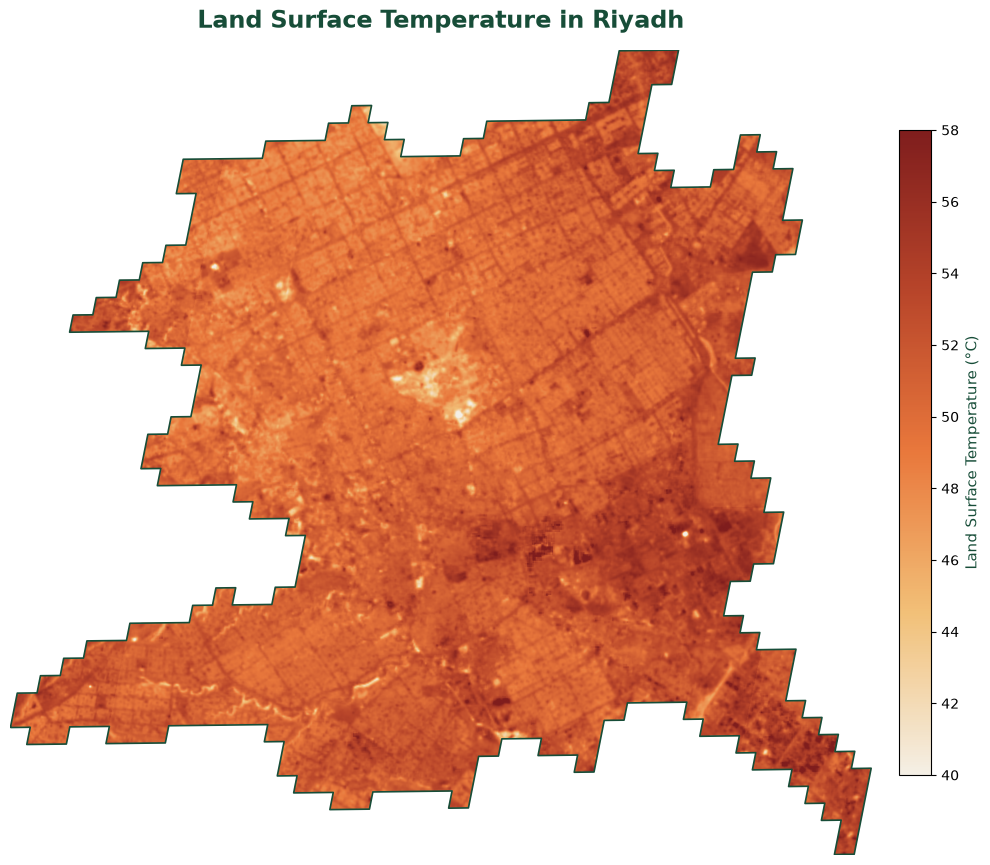

Saved website LST map to:
C:\Users\Alhaylam Alajmi\Desktop\MUSA 5500\Final Project\website\assets\images\maps\Riyadh_LST_Map.png


In [25]:
# Export a presentation-ready LST map for the website

import matplotlib.pyplot as plt
import rasterio
from rasterio.plot import show
from matplotlib.colors import LinearSegmentedColormap

# Paths
lst_map_output = (
    project_root
    / "website"
    / "assets"
    / "images"
    / "maps"
    / "Riyadh_LST_Map.png"
)

lst_map_output.parent.mkdir(
    parents=True,
    exist_ok=True
)

# Heat-oriented color palette
heat_cmap = LinearSegmentedColormap.from_list(
    "riyadh_heat",
    [
        "#F4EFE5",
        "#F2C078",
        "#E9783C",
        "#B8452A",
        "#7F1D1D"
    ],
    N=256
)

# Read the final LST raster
with rasterio.open(lst_final_path) as src:
    lst_data = src.read(1, masked=True)
    lst_extent = [
        src.bounds.left,
        src.bounds.right,
        src.bounds.bottom,
        src.bounds.top
    ]

# Plot
fig, ax = plt.subplots(figsize=(10, 10))

image = ax.imshow(
    lst_data,
    cmap=heat_cmap,
    extent=lst_extent,
    origin="upper",
    vmin=40,
    vmax=58
)

# Riyadh boundary
riyadh_boundary_metric.boundary.plot(
    ax=ax,
    color="#174D38",
    linewidth=1.2
)

ax.set_title(
    "Land Surface Temperature in Riyadh",
    fontsize=17,
    color="#174D38",
    fontweight="bold",
    pad=16
)

cbar = fig.colorbar(
    image,
    ax=ax,
    fraction=0.035,
    pad=0.03
)

cbar.set_label(
    "Land Surface Temperature (°C)",
    fontsize=11,
    color="#174D38"
)

ax.set_axis_off()

fig.patch.set_facecolor("white")
ax.set_facecolor("#FAF7F0")

plt.tight_layout()

plt.savefig(
    lst_map_output,
    dpi=220,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Saved website LST map to:")
print(lst_map_output)

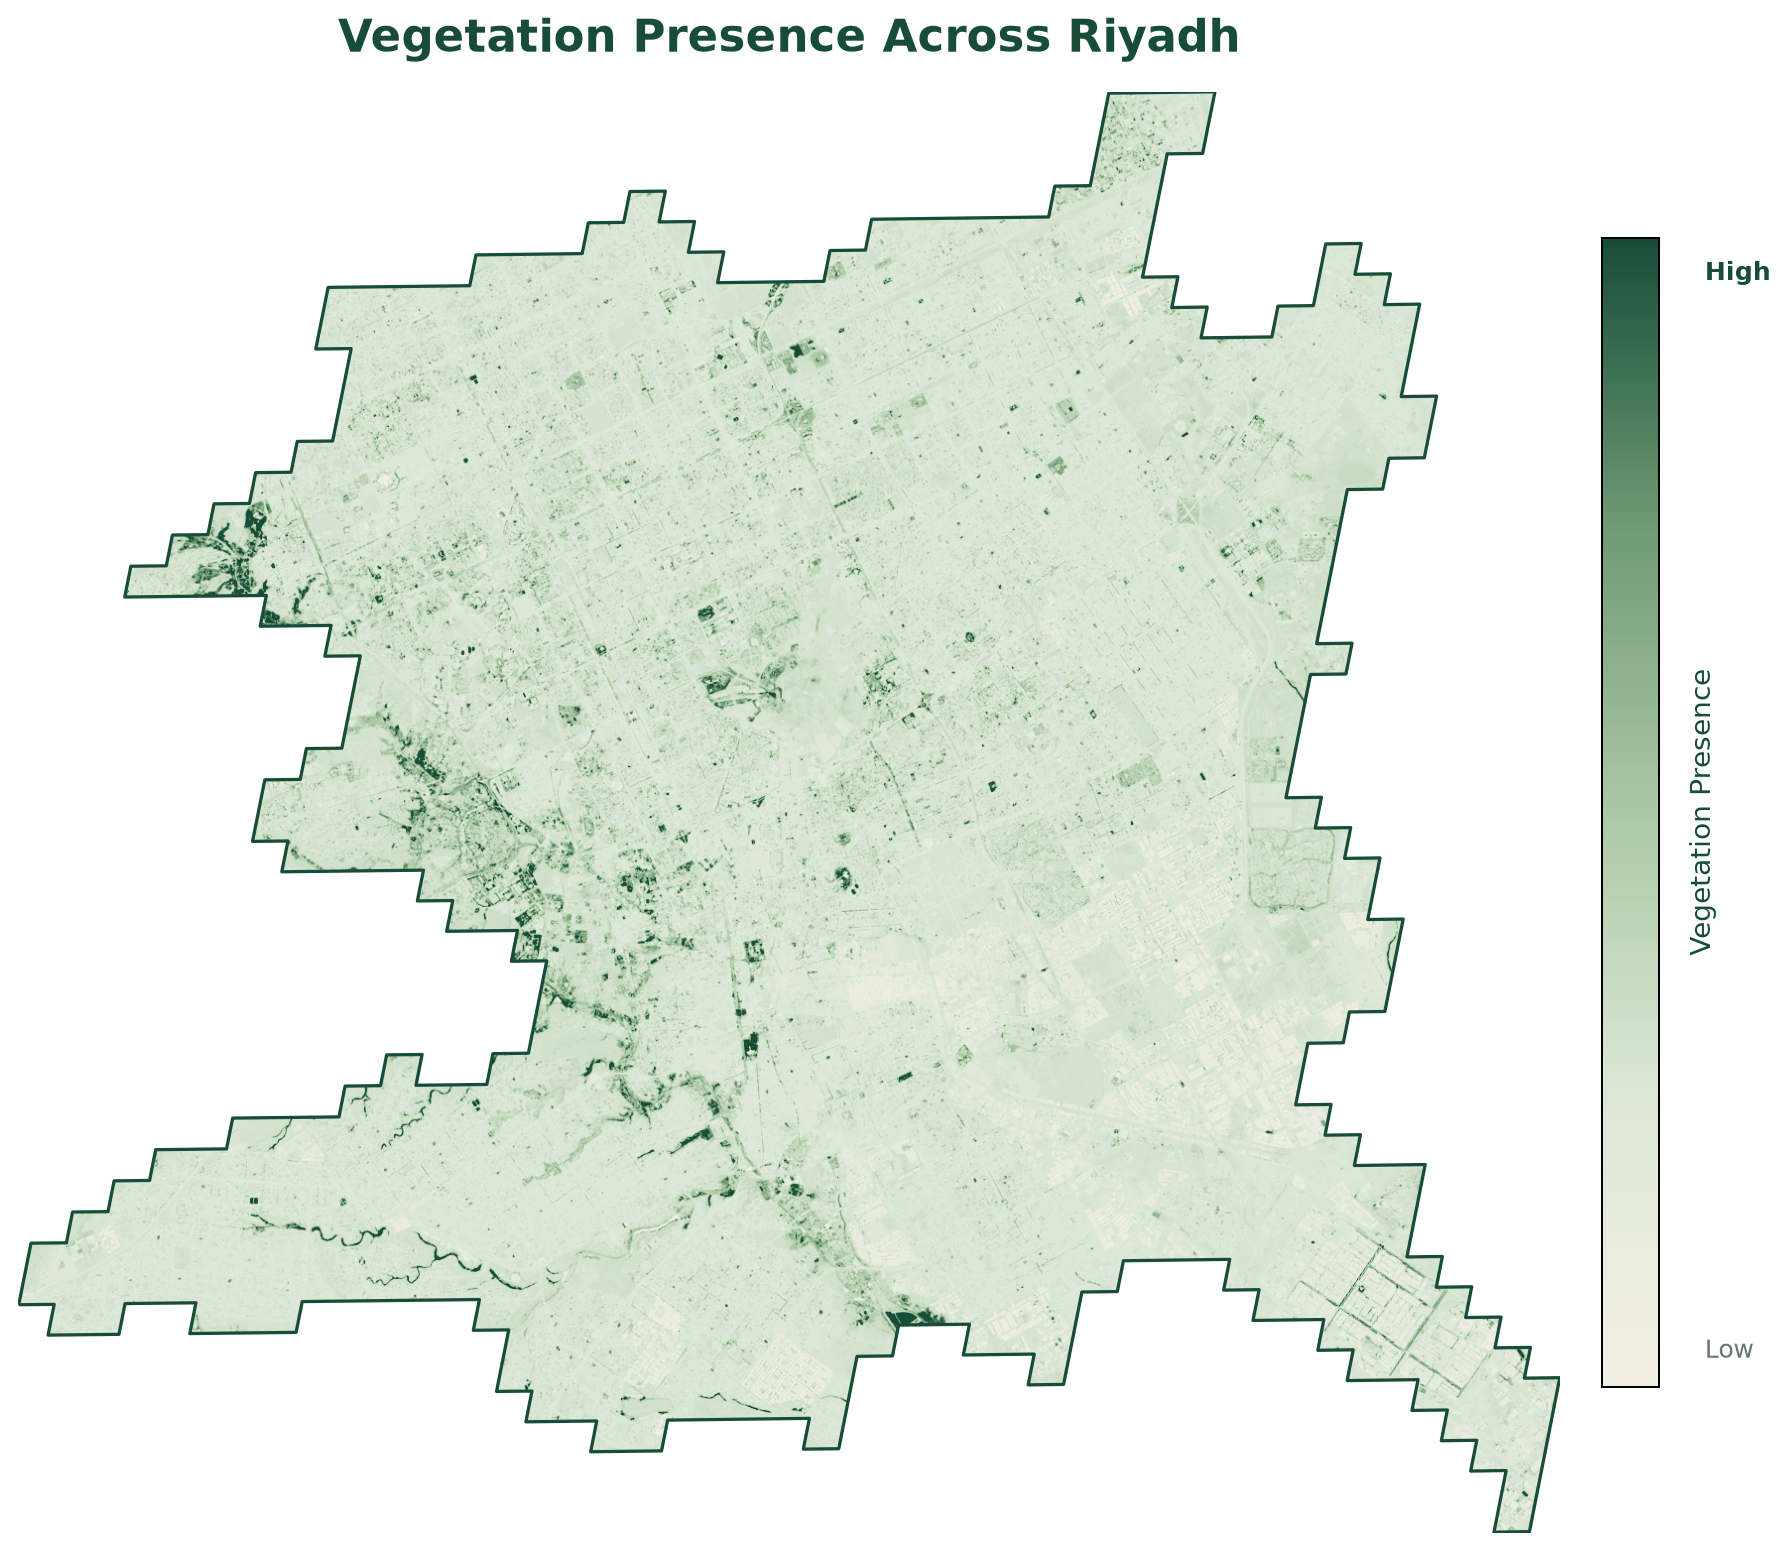

NDVI map saved to:
C:\Users\Alhaylam Alajmi\Desktop\MUSA 5500\Final Project\website\assets\images\maps\Riyadh_NDVI_Map.png


In [30]:
from pathlib import Path

import matplotlib.pyplot as plt
import rasterio
import geopandas as gpd
import numpy as np
from matplotlib.colors import LinearSegmentedColormap

# ---------------------------------------------------------
# Project paths
# ---------------------------------------------------------

project_dir = Path(
    r"C:\Users\Alhaylam Alajmi\Desktop\MUSA 5500\Final Project"
)

ndvi_path = (
    project_dir
    / "outputs"
    / "rasters"
    / "Riyadh_NDVI_2026.tif"
)

boundary_path = (
    project_dir
    / "Data"
    / "boundary"
    / "Riyadh_Urban_Boundary.gpkg"
)

ndvi_png_path = (
    project_dir
    / "website"
    / "assets"
    / "images"
    / "maps"
    / "Riyadh_NDVI_Map.png"
)

ndvi_png_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

# ---------------------------------------------------------
# Load Riyadh boundary
# ---------------------------------------------------------

riyadh_boundary = gpd.read_file(boundary_path)

# ---------------------------------------------------------
# Read NDVI raster
# ---------------------------------------------------------

with rasterio.open(ndvi_path) as src:
    ndvi_data = src.read(1).astype("float32")
    ndvi_bounds = src.bounds
    ndvi_nodata = src.nodata
    ndvi_crs = src.crs

if ndvi_nodata is not None:
    ndvi_data[ndvi_data == ndvi_nodata] = np.nan

# ---------------------------------------------------------
# Vegetation color palette
# ---------------------------------------------------------

ndvi_colors = [
    "#F4EFE5",
    "#DCE8D7",
    "#ABC8A4",
    "#6F9A74",
    "#174D38"
]

ndvi_cmap = LinearSegmentedColormap.from_list(
    "riyadh_ndvi",
    ndvi_colors
)

# ---------------------------------------------------------
# Plot
# ---------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(10, 10),
    dpi=180
)

img = ax.imshow(
    ndvi_data,
    cmap=ndvi_cmap,
    vmin=-0.05,
    vmax=0.40,
    extent=[
        ndvi_bounds.left,
        ndvi_bounds.right,
        ndvi_bounds.bottom,
        ndvi_bounds.top
    ]
)

boundary_for_ndvi = riyadh_boundary.to_crs(ndvi_crs)

boundary_for_ndvi.boundary.plot(
    ax=ax,
    color="#174D38",
    linewidth=1.3
)

# ---------------------------------------------------------
# Styling
# ---------------------------------------------------------

ax.set_title(
    "Vegetation Presence Across Riyadh",
    fontsize=18,
    fontweight="bold",
    color="#174D38",
    pad=16
)

ax.set_axis_off()

cbar = fig.colorbar(
    img,
    ax=ax,
    fraction=0.035,
    pad=0.025
)

# Remove numeric tick labels
cbar.set_ticks([])

cbar.ax.text(
    1.8,
    0.02,
    "Low",
    transform=cbar.ax.transAxes,
    ha="left",
    va="bottom",
    fontsize=10,
    color="#65766D"
)

cbar.ax.text(
    1.8,
    0.98,
    "High",
    transform=cbar.ax.transAxes,
    ha="left",
    va="top",
    fontsize=10,
    color="#174D38",
    fontweight="bold"
)

cbar.set_label(
    "Vegetation Presence",
    fontsize=11,
    color="#174D38",
    labelpad=12
)

plt.tight_layout()

# ---------------------------------------------------------
# Save PNG
# ---------------------------------------------------------

plt.savefig(
    ndvi_png_path,
    dpi=180,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("NDVI map saved to:")
print(ndvi_png_path)

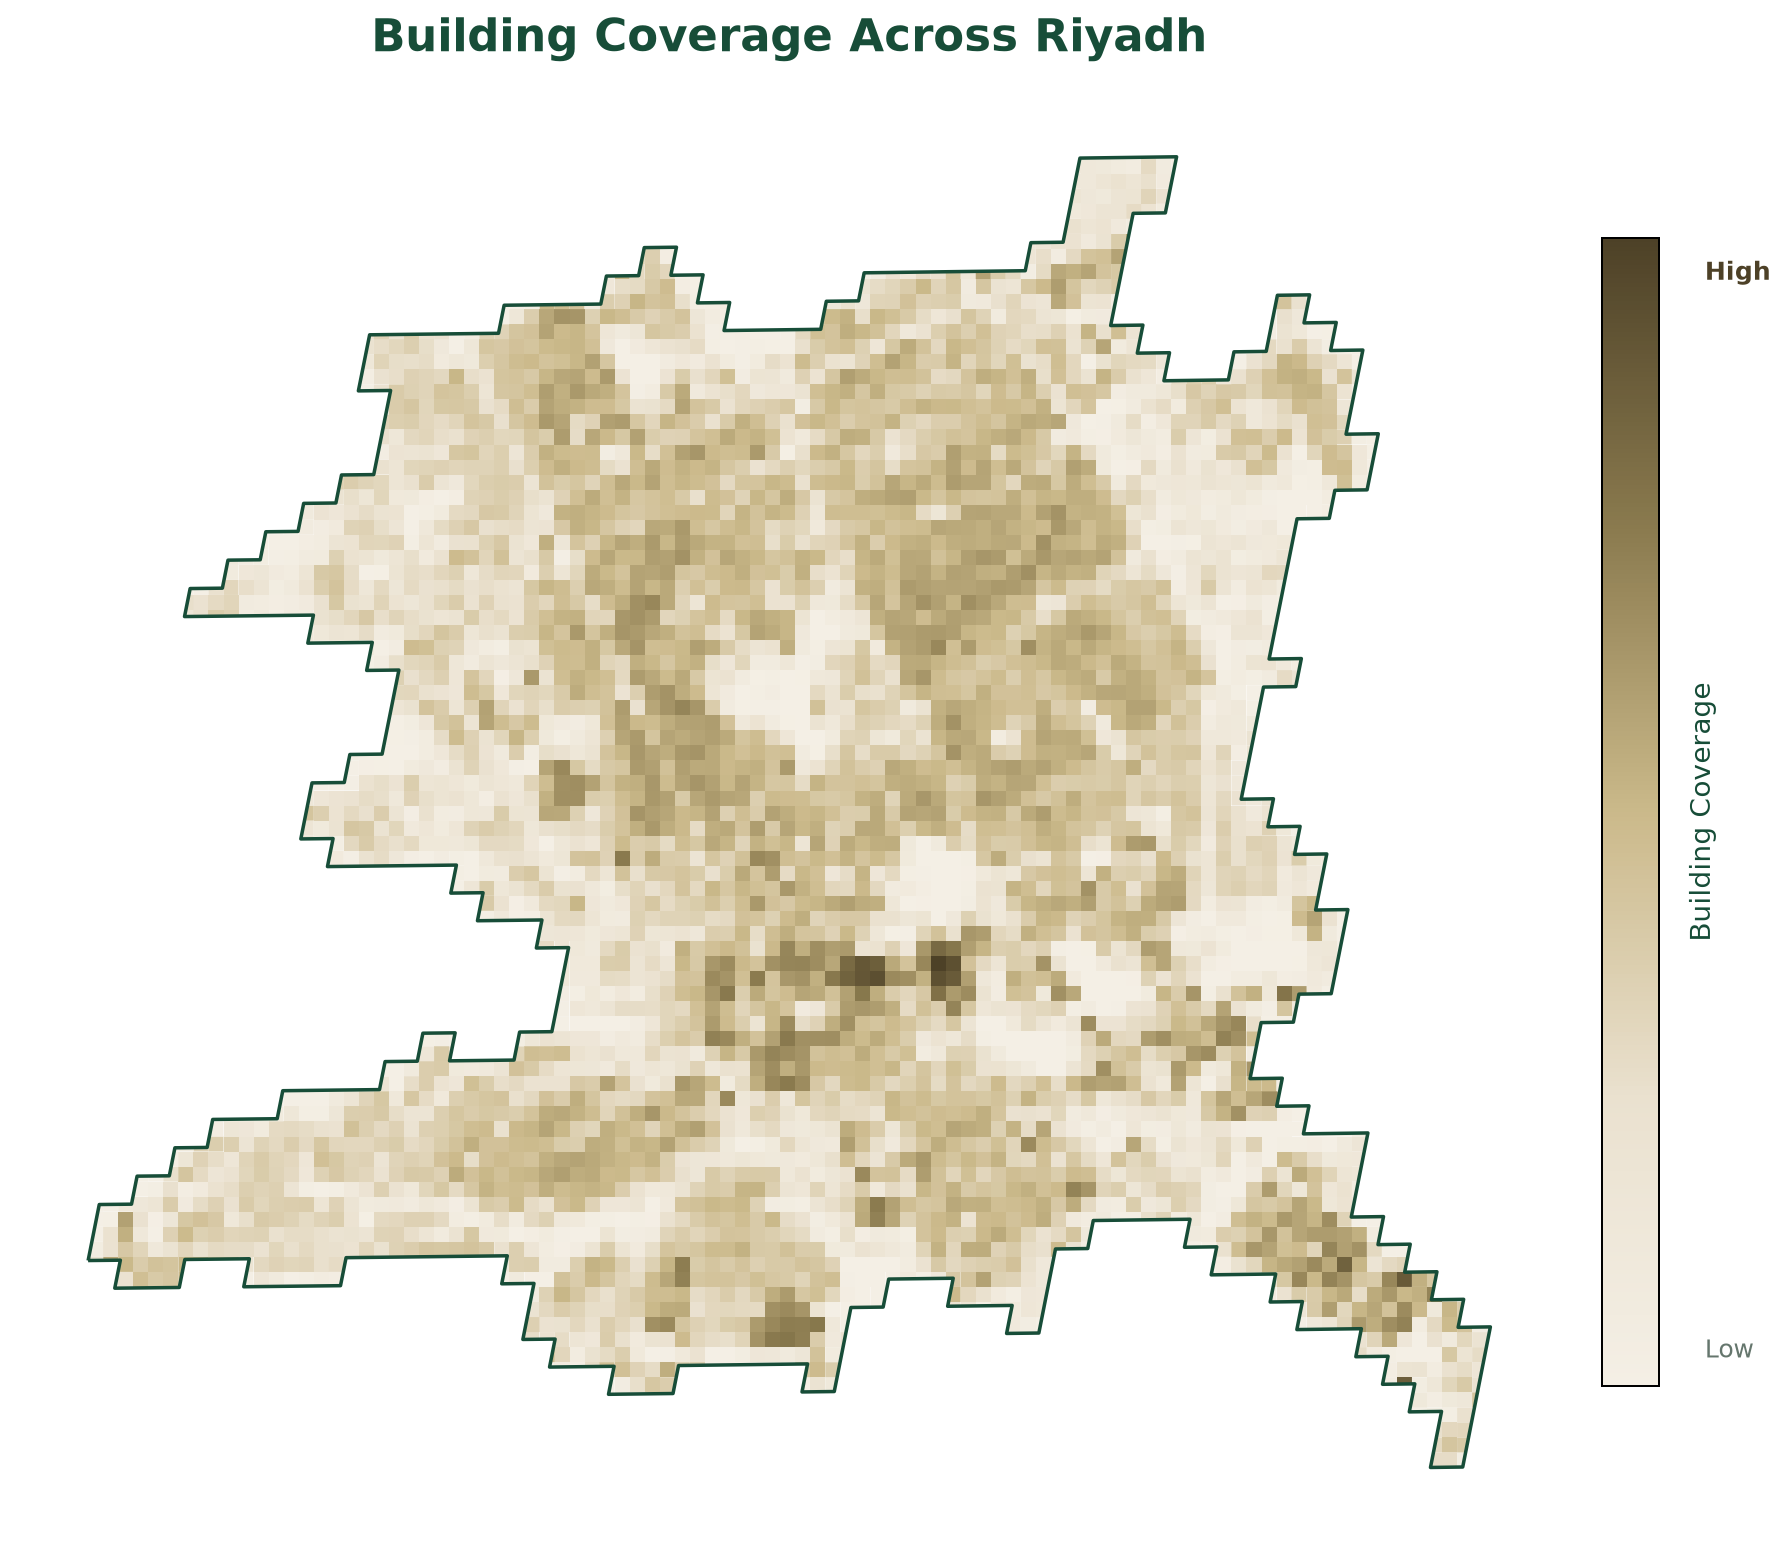

Building coverage map saved to:
C:\Users\Alhaylam Alajmi\Desktop\MUSA 5500\Final Project\website\assets\images\maps\Riyadh_Building_Coverage_Map.png


In [31]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# ---------------------------------------------------------
# Project paths
# ---------------------------------------------------------

project_dir = Path(
    r"C:\Users\Alhaylam Alajmi\Desktop\MUSA 5500\Final Project"
)

building_grid_path = (
    project_dir
    / "Data"
    / "building_footprints"
    / "Riyadh_500m_Grid_Building_Metrics.gpkg"
)

boundary_path = (
    project_dir
    / "Data"
    / "boundary"
    / "Riyadh_Urban_Boundary.gpkg"
)

building_png_path = (
    project_dir
    / "website"
    / "assets"
    / "images"
    / "maps"
    / "Riyadh_Building_Coverage_Map.png"
)

building_png_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

# ---------------------------------------------------------
# Load data
# ---------------------------------------------------------

building_grid = gpd.read_file(building_grid_path)
riyadh_boundary = gpd.read_file(boundary_path)

# Reproject boundary to match grid
riyadh_boundary_grid = riyadh_boundary.to_crs(building_grid.crs)

# ---------------------------------------------------------
# Saudi project palette
# ---------------------------------------------------------

building_colors = [
    "#F4EFE5",
    "#EAE1CF",
    "#CBB98A",
    "#8A7A4E",
    "#4D4127"
]

building_cmap = LinearSegmentedColormap.from_list(
    "riyadh_building_coverage",
    building_colors
)

# ---------------------------------------------------------
# Plot
# ---------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(10, 10),
    dpi=180
)

building_grid.plot(
    column="building_coverage_pct",
    cmap=building_cmap,
    linewidth=0,
    ax=ax,
    vmin=0,
    vmax=70
)

riyadh_boundary_grid.boundary.plot(
    ax=ax,
    color="#174D38",
    linewidth=1.4
)

# ---------------------------------------------------------
# Styling
# ---------------------------------------------------------

ax.set_title(
    "Building Coverage Across Riyadh",
    fontsize=18,
    fontweight="bold",
    color="#174D38",
    pad=16
)

ax.set_axis_off()

# Manual colorbar without numeric labels
sm = plt.cm.ScalarMappable(
    cmap=building_cmap,
    norm=plt.Normalize(vmin=0, vmax=70)
)

sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=ax,
    fraction=0.035,
    pad=0.025
)

cbar.set_ticks([])

cbar.ax.text(
    1.8,
    0.02,
    "Low",
    transform=cbar.ax.transAxes,
    ha="left",
    va="bottom",
    fontsize=10,
    color="#65766D"
)

cbar.ax.text(
    1.8,
    0.98,
    "High",
    transform=cbar.ax.transAxes,
    ha="left",
    va="top",
    fontsize=10,
    color="#4D4127",
    fontweight="bold"
)

cbar.set_label(
    "Building Coverage",
    fontsize=11,
    color="#174D38",
    labelpad=12
)

plt.tight_layout()

# ---------------------------------------------------------
# Save PNG
# ---------------------------------------------------------

plt.savefig(
    building_png_path,
    dpi=180,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Building coverage map saved to:")
print(building_png_path)

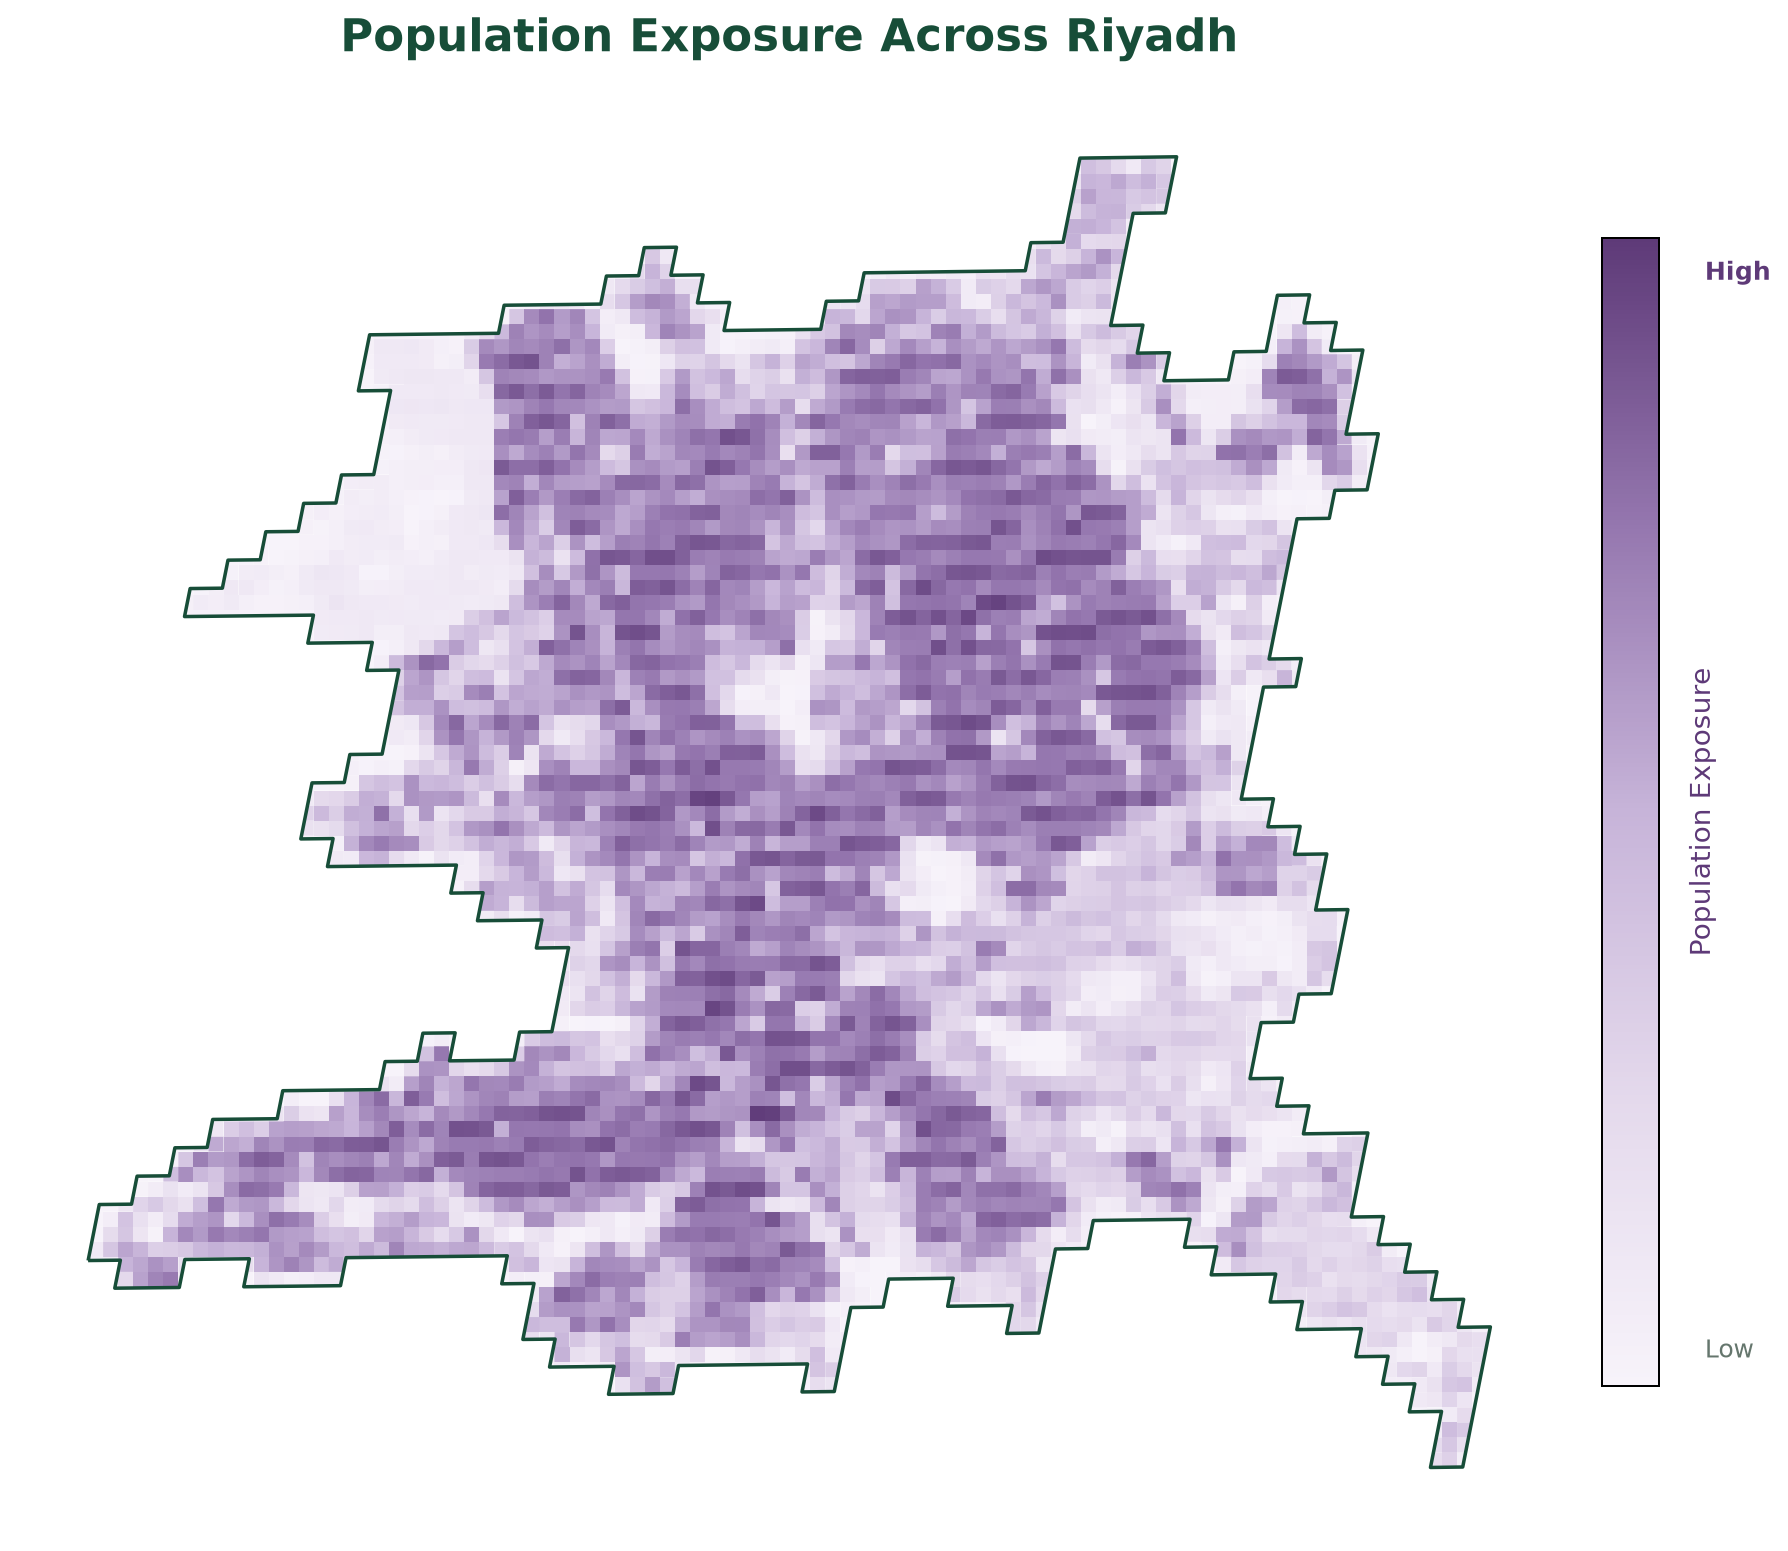

Population exposure map saved to:
C:\Users\Alhaylam Alajmi\Desktop\MUSA 5500\Final Project\website\assets\images\maps\Riyadh_Population_Exposure_Map.png


In [34]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# ---------------------------------------------------------
# Project paths
# ---------------------------------------------------------

project_dir = Path(
    r"C:\Users\Alhaylam Alajmi\Desktop\MUSA 5500\Final Project"
)

population_grid_path = (
    project_dir
    / "Data"
    / "Population"
    / "Riyadh_500m_Grid_Buildings_Population.gpkg"
)

boundary_path = (
    project_dir
    / "Data"
    / "boundary"
    / "Riyadh_Urban_Boundary.gpkg"
)

population_png_path = (
    project_dir
    / "website"
    / "assets"
    / "images"
    / "maps"
    / "Riyadh_Population_Exposure_Map.png"
)

population_png_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

# ---------------------------------------------------------
# Load data
# ---------------------------------------------------------

population_grid = gpd.read_file(population_grid_path)
riyadh_boundary = gpd.read_file(boundary_path)

riyadh_boundary_grid = riyadh_boundary.to_crs(population_grid.crs)

# ---------------------------------------------------------
# Population palette
# ---------------------------------------------------------

population_colors = [
    "#F7F3FA",
    "#E4D9EC",
    "#C7B4D9",
    "#9577AF",
    "#5E3A78"
]

population_cmap = LinearSegmentedColormap.from_list(
    "riyadh_population",
    population_colors
)

# ---------------------------------------------------------
# Plot
# ---------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(10, 10),
    dpi=180
)

population_grid.plot(
    column="population",
    cmap=population_cmap,
    linewidth=0,
    ax=ax,
    vmin=0,
    vmax=3000
)

riyadh_boundary_grid.boundary.plot(
    ax=ax,
    color="#174D38",
    linewidth=1.4
)

# ---------------------------------------------------------
# Styling
# ---------------------------------------------------------

ax.set_title(
    "Population Exposure Across Riyadh",
    fontsize=18,
    fontweight="bold",
    color="#174D38",
    pad=16
)

ax.set_axis_off()

sm = plt.cm.ScalarMappable(
    cmap=population_cmap,
    norm=plt.Normalize(vmin=0, vmax=3000)
)

sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=ax,
    fraction=0.035,
    pad=0.025
)

cbar.set_ticks([])

cbar.ax.text(
    1.8,
    0.02,
    "Low",
    transform=cbar.ax.transAxes,
    ha="left",
    va="bottom",
    fontsize=10,
    color="#65766D"
)

cbar.ax.text(
    1.8,
    0.98,
    "High",
    transform=cbar.ax.transAxes,
    ha="left",
    va="top",
    fontsize=10,
    color="#5E3A78",
    fontweight="bold"
)

cbar.set_label(
    "Population Exposure",
    fontsize=11,
    color="#5E3A78",
    labelpad=12
)

plt.tight_layout()

# ---------------------------------------------------------
# Save PNG
# ---------------------------------------------------------

plt.savefig(
    population_png_path,
    dpi=180,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Population exposure map saved to:")
print(population_png_path)

<div style="background:#FAF7F0; padding:14px 18px; border-left:6px solid #C5A45A; border-radius:8px; margin:14px 0;">

<h2 style="color:#174D38; margin:0 0 6px 0;">
10. Integrate NDVI and LST with the 500 m Grid
</h2>

<p style="color:#2B2B2B; margin:0; line-height:1.6;">
This section summarizes the final NDVI and land surface temperature rasters within each 500 m grid cell. The resulting grid will combine built environment, population, vegetation, and urban heat indicators in a common spatial analysis framework.
</p>

</div>

In [24]:
# Summarize NDVI and LST within each 500 m grid cell

from rasterstats import zonal_stats

# Calculate mean NDVI per grid cell
ndvi_stats = zonal_stats(
    riyadh_grid_population,
    ndvi_final_path,
    stats=["mean"],
    nodata=np.nan
)

# Calculate mean LST per grid cell
lst_stats = zonal_stats(
    riyadh_grid_population,
    lst_final_path,
    stats=["mean"],
    nodata=np.nan
)

# Create the combined analysis grid
riyadh_grid_analysis = riyadh_grid_population.copy()

riyadh_grid_analysis["mean_ndvi"] = [
    stat["mean"] if stat["mean"] is not None else np.nan
    for stat in ndvi_stats
]

riyadh_grid_analysis["mean_lst_c"] = [
    stat["mean"] if stat["mean"] is not None else np.nan
    for stat in lst_stats
]

print("Grid cells:", len(riyadh_grid_analysis))
print(
    "Cells with valid NDVI:",
    riyadh_grid_analysis["mean_ndvi"].notna().sum()
)
print(
    "Cells with valid LST:",
    riyadh_grid_analysis["mean_lst_c"].notna().sum()
)
print(
    "Mean grid NDVI:",
    round(riyadh_grid_analysis["mean_ndvi"].mean(), 3)
)
print(
    "Mean grid LST:",
    round(riyadh_grid_analysis["mean_lst_c"].mean(), 2),
    "°C"
)

Grid cells: 4721
Cells with valid NDVI: 4700
Cells with valid LST: 4700
Mean grid NDVI: 0.08
Mean grid LST: 51.1 °C


<div style="background:#FAF7F0; padding:14px 18px; border-left:6px solid #174D38; border-radius:8px; margin:14px 0;">

<h2 style="color:#174D38; margin:0 0 6px 0;">
11. Build the Final Analysis Dataset
</h2>

<p style="color:#2B2B2B; margin:0; line-height:1.6;">
The final analysis dataset combines building, population, vegetation, and land surface temperature indicators for each 500 m grid cell. Small boundary fragments without valid Landsat observations will be excluded so all retained cells contain the variables required for subsequent spatial and statistical analysis.
</p>

</div>

In [25]:
# Build the final analysis dataset

final_analysis_grid = riyadh_grid_analysis.dropna(
    subset=[
        "mean_ndvi",
        "mean_lst_c"
    ]
).copy()

final_analysis_grid = final_analysis_grid.reset_index(drop=True)

print("Original grid cells:", len(riyadh_grid_analysis))
print("Final analysis grid cells:", len(final_analysis_grid))
print(
    "Excluded boundary fragments:",
    len(riyadh_grid_analysis) - len(final_analysis_grid)
)

print()
print("Final dataset columns:")
print(final_analysis_grid.columns.tolist())

Original grid cells: 4721
Final analysis grid cells: 4700
Excluded boundary fragments: 21

Final dataset columns:
['geometry', 'grid_id', 'building_count', 'building_area_m2', 'grid_area_m2', 'building_coverage_pct', 'population', 'mean_ndvi', 'mean_lst_c']


In [26]:
# Save the final 500 m analysis dataset

final_grid_output = (
    project_root
    / "outputs"
    / "Riyadh_500m_Final_Analysis_Grid.gpkg"
)

final_analysis_grid.to_file(
    final_grid_output,
    driver="GPKG"
)

print("Saved final analysis grid to:")
print(final_grid_output)

Saved final analysis grid to:
C:\Users\Alhaylam Alajmi\Desktop\MUSA 5500\Final Project\outputs\Riyadh_500m_Final_Analysis_Grid.gpkg


<div style="background:#FAF7F0; padding:14px 18px; border-left:6px solid #C5A45A; border-radius:8px; margin:14px 0;">

<h2 style="color:#174D38; margin:0 0 6px 0;">
12. Exploratory Analysis of Urban Heat and Greening Indicators
</h2>

<p style="color:#2B2B2B; margin:0; line-height:1.6;">
This section explores the initial relationships among land surface temperature, vegetation, population, and building coverage across the 500 m analysis grid. The goal is to identify broad spatial and statistical patterns before applying more advanced analytical methods.
</p>

</div>

In [27]:
# Summarize the main variables in the final analysis dataset

analysis_columns = [
    "population",
    "building_count",
    "building_coverage_pct",
    "mean_ndvi",
    "mean_lst_c"
]

summary_statistics = (
    final_analysis_grid[analysis_columns]
    .describe()
    .round(2)
)

summary_statistics

,population,building_count,building_coverage_pct,mean_ndvi,mean_lst_c
count,4700.00,4700.00,4700.00,4700.00,4700.00
mean,1336.53,135.34,22.48,0.08,51.10
std,814.91,108.37,13.32,0.03,1.82
min,0.00,0.00,0.00,-0.03,40.72
25%,601.13,42.00,11.56,0.07,49.90
50%,1426.70,119.50,23.71,0.07,50.95
75%,2054.95,206.00,32.73,0.09,52.21
max,2961.53,687.00,69.90,0.42,57.73


In [28]:
# Calculate correlations among the main analysis variables

correlation_matrix = (
    final_analysis_grid[
        [
            "population",
            "building_count",
            "building_coverage_pct",
            "mean_ndvi",
            "mean_lst_c"
        ]
    ]
    .corr()
    .round(2)
)

correlation_matrix

,population,building_count,building_coverage_pct,mean_ndvi,mean_lst_c
population,1.00,0.73,0.69,-0.10,-0.23
building_count,0.73,1.00,0.64,-0.10,-0.32
building_coverage_pct,0.69,0.64,1.00,-0.34,-0.10
mean_ndvi,-0.10,-0.10,-0.34,1.00,-0.38
mean_lst_c,-0.23,-0.32,-0.10,-0.38,1.00


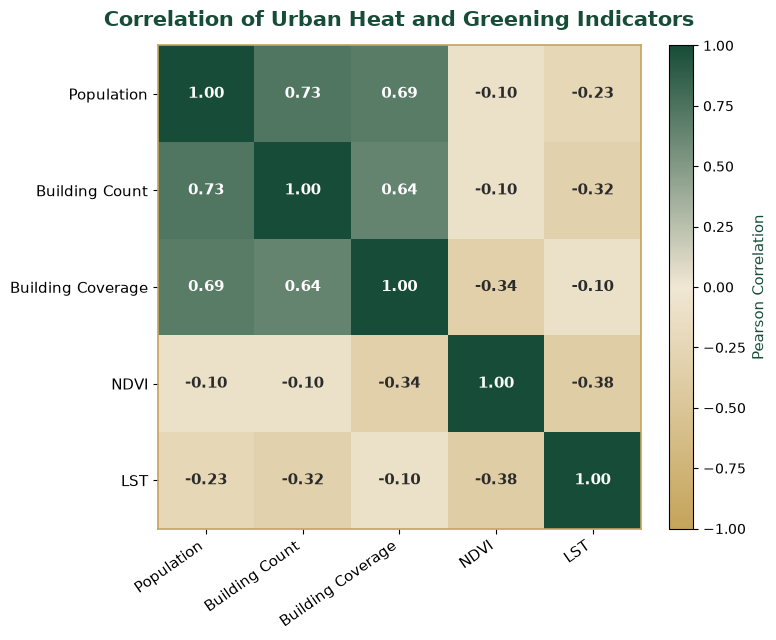

In [29]:
# Visualize correlations using the project color palette

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

labels = [
    "Population",
    "Building Count",
    "Building Coverage",
    "NDVI",
    "LST"
]

# Project palette:
# negative = muted gold
# neutral = ivory
# positive = Saudi green
saudi_corr_cmap = LinearSegmentedColormap.from_list(
    "saudi_corr",
    [
        "#C5A45A",
        "#F0E7D4",
        "#174D38"
    ],
    N=256
)

fig, ax = plt.subplots(figsize=(8.5, 6.5))
fig.patch.set_facecolor("white")
ax.set_facecolor("#FCFAF5")

image = ax.imshow(
    correlation_matrix.values,
    cmap=saudi_corr_cmap,
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(labels)))
ax.set_yticks(range(len(labels)))

ax.set_xticklabels(
    labels,
    rotation=35,
    ha="right",
    fontsize=11
)

ax.set_yticklabels(
    labels,
    fontsize=11
)

# Add correlation values inside cells
for i in range(len(labels)):
    for j in range(len(labels)):
        value = correlation_matrix.iloc[i, j]

        if value >= 0.55:
            text_color = "white"
        else:
            text_color = "#2B2B2B"

        ax.text(
            j,
            i,
            f"{value:.2f}",
            ha="center",
            va="center",
            color=text_color,
            fontsize=11,
            fontweight="bold"
        )

ax.set_title(
    "Correlation of Urban Heat and Greening Indicators",
    fontsize=15,
    color="#174D38",
    fontweight="bold",
    pad=14
)

cbar = fig.colorbar(
    image,
    ax=ax,
    fraction=0.046,
    pad=0.04
)

cbar.set_label(
    "Pearson Correlation",
    fontsize=11,
    color="#174D38"
)

for spine in ax.spines.values():
    spine.set_edgecolor("#C5A45A")
    spine.set_linewidth(1.2)

plt.tight_layout()
plt.show()

<div style="background:#FAF7F0; padding:12px 16px; border-left:5px solid #C5A45A; border-radius:8px; margin:12px 0;">

<p style="color:#2B2B2B; margin:0; line-height:1.6;">
The strongest relationship with land surface temperature is observed for NDVI (r = -0.38), indicating that greener grid cells generally tend to have lower surface temperatures. Population and building count also show negative correlations with LST, although these relationships should be interpreted cautiously because they may reflect broader spatial differences between dense urban areas and surrounding exposed land.
</p>

</div>

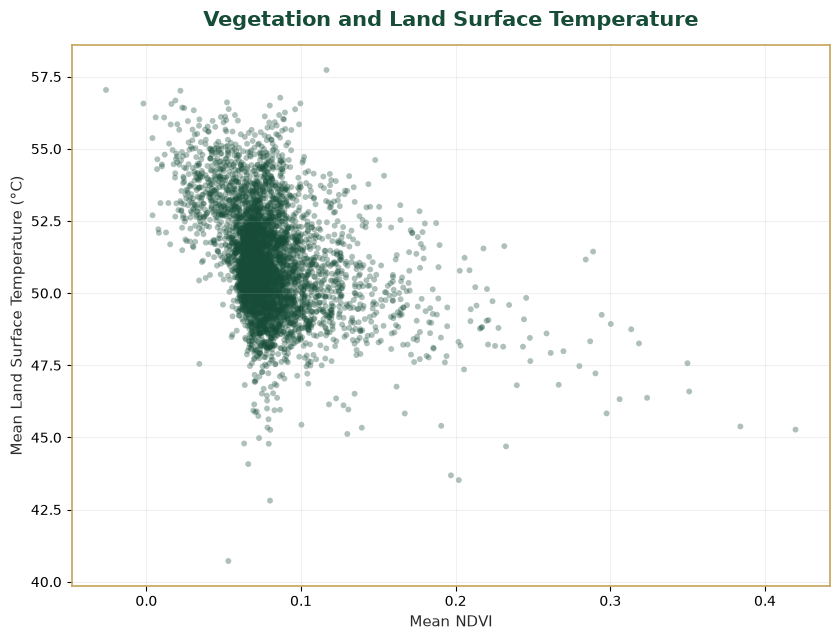

In [30]:
# Explore the relationship between NDVI and land surface temperature
# using the project color palette

fig, ax = plt.subplots(figsize=(8.5, 6.5))

ax.scatter(
    final_analysis_grid["mean_ndvi"],
    final_analysis_grid["mean_lst_c"],
    s=18,
    alpha=0.35,
    color="#174D38",
    edgecolors="none"
)

ax.set_title(
    "Vegetation and Land Surface Temperature",
    fontsize=15,
    color="#174D38",
    fontweight="bold",
    pad=14
)

ax.set_xlabel(
    "Mean NDVI",
    fontsize=11,
    color="#2B2B2B"
)

ax.set_ylabel(
    "Mean Land Surface Temperature (°C)",
    fontsize=11,
    color="#2B2B2B"
)

ax.grid(
    True,
    alpha=0.18
)

for spine in ax.spines.values():
    spine.set_edgecolor("#C5A45A")
    spine.set_linewidth(1.2)

plt.tight_layout()
plt.show()

<div style="background:#FAF7F0; padding:12px 16px; border-left:5px solid #C5A45A; border-radius:8px; margin:12px 0;">

<p style="color:#2B2B2B; margin:0; line-height:1.6;">
The scatter plot shows a general negative relationship between vegetation and land surface temperature. Grid cells with higher NDVI values tend to have lower surface temperatures, although substantial variation remains across the city. This suggests that vegetation may contribute to local cooling, but other urban and spatial factors also influence surface temperature patterns.
</p>

</div>

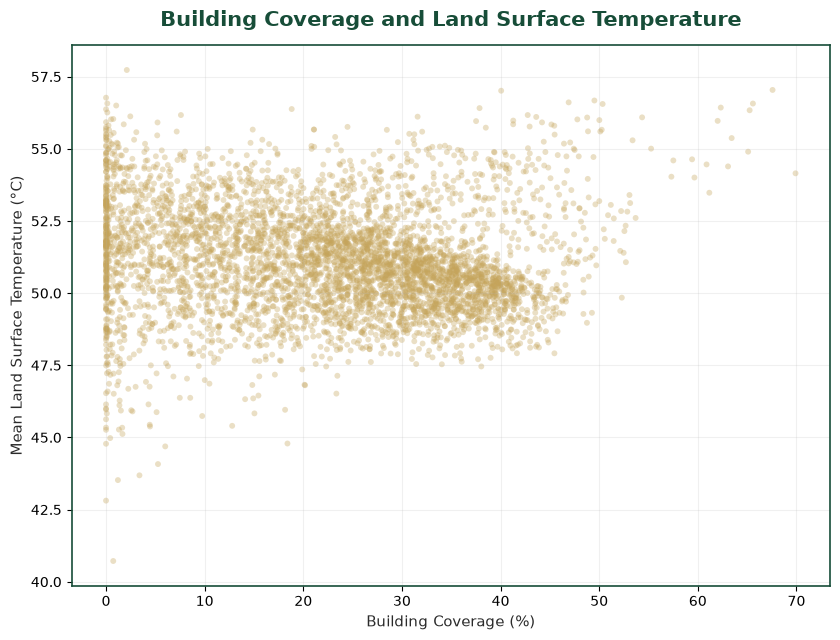

In [31]:
# Explore the relationship between building coverage and land surface temperature

fig, ax = plt.subplots(figsize=(8.5, 6.5))

ax.scatter(
    final_analysis_grid["building_coverage_pct"],
    final_analysis_grid["mean_lst_c"],
    s=18,
    alpha=0.35,
    color="#C5A45A",
    edgecolors="none"
)

ax.set_title(
    "Building Coverage and Land Surface Temperature",
    fontsize=15,
    color="#174D38",
    fontweight="bold",
    pad=14
)

ax.set_xlabel(
    "Building Coverage (%)",
    fontsize=11,
    color="#2B2B2B"
)

ax.set_ylabel(
    "Mean Land Surface Temperature (°C)",
    fontsize=11,
    color="#2B2B2B"
)

ax.grid(
    True,
    alpha=0.18
)

for spine in ax.spines.values():
    spine.set_edgecolor("#174D38")
    spine.set_linewidth(1.2)

plt.tight_layout()
plt.show()

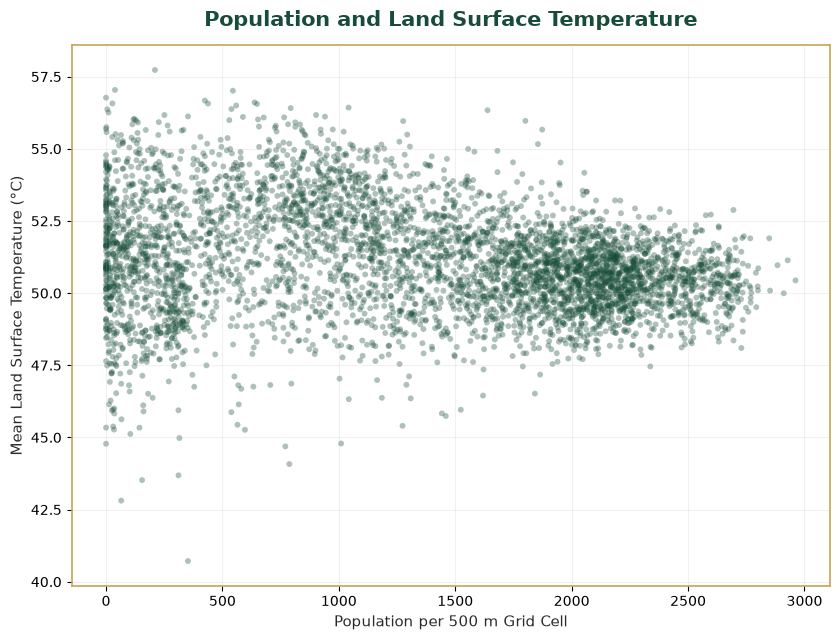

In [32]:
# Explore the relationship between population and land surface temperature

fig, ax = plt.subplots(figsize=(8.5, 6.5))

ax.scatter(
    final_analysis_grid["population"],
    final_analysis_grid["mean_lst_c"],
    s=18,
    alpha=0.35,
    color="#174D38",
    edgecolors="none"
)

ax.set_title(
    "Population and Land Surface Temperature",
    fontsize=15,
    color="#174D38",
    fontweight="bold",
    pad=14
)

ax.set_xlabel(
    "Population per 500 m Grid Cell",
    fontsize=11,
    color="#2B2B2B"
)

ax.set_ylabel(
    "Mean Land Surface Temperature (°C)",
    fontsize=11,
    color="#2B2B2B"
)

ax.grid(
    True,
    alpha=0.18
)

for spine in ax.spines.values():
    spine.set_edgecolor("#C5A45A")
    spine.set_linewidth(1.2)

plt.tight_layout()
plt.show()

<div style="background:#FAF7F0; padding:12px 16px; border-left:5px solid #C5A45A; border-radius:8px; margin:12px 0;">

<p style="color:#2B2B2B; margin:0; line-height:1.6;">
Population shows a weak negative relationship with land surface temperature (r = -0.23). More populated grid cells are generally concentrated within a narrower temperature range, while sparsely populated cells show greater thermal variation. This pattern should not be interpreted as a direct cooling effect of population, but rather as a spatial difference between densely occupied urban areas and more exposed peripheral land.
</p>

</div>

<div style="background:#FAF7F0; padding:14px 18px; border-left:6px solid #174D38; border-radius:8px; margin:14px 0;">

<h2 style="color:#174D38; margin:0 0 6px 0;">
13. Export Final Dataset and Notebook Summary
</h2>

<p style="color:#2B2B2B; margin:0; line-height:1.6;">
This final section confirms the processed analysis dataset, exports the key variables for use in later modeling and visualization, and summarizes the main outputs prepared in this notebook.
</p>

</div>

In [33]:
# Export the final analysis table as CSV

final_csv_output = (
    project_root
    / "outputs"
    / "Riyadh_500m_Final_Analysis_Table.csv"
)

final_analysis_grid.drop(
    columns="geometry"
).to_csv(
    final_csv_output,
    index=False
)

print("Saved final analysis table to:")
print(final_csv_output)

Saved final analysis table to:
C:\Users\Alhaylam Alajmi\Desktop\MUSA 5500\Final Project\outputs\Riyadh_500m_Final_Analysis_Table.csv


<div style="background:#FAF7F0; padding:14px 18px; border-left:6px solid #C5A45A; border-radius:8px; margin:14px 0;">

<h3 style="color:#174D38; margin:0 0 8px 0;">
Notebook Summary
</h3>

<p style="color:#2B2B2B; margin:0; line-height:1.7;">
This notebook prepared the core geospatial dataset for the Cooling Riyadh project. Microsoft building footprints were processed and summarized within a 500 m analysis grid, WorldPop population estimates were integrated, and Landsat imagery was used to derive NDVI and land surface temperature. The final dataset contains 4,700 valid grid cells with consistent indicators for population, building characteristics, vegetation, and urban heat. Initial exploratory analysis shows that NDVI has the strongest negative relationship with land surface temperature among the variables examined, providing a foundation for the next stage of spatial prioritization and machine learning analysis.
</p>

</div>